# Map and Environment

In [1]:
import os
import pickle

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from dotenv import find_dotenv, load_dotenv
from matplotlib import gridspec
from matplotlib.lines import Line2D
import matplotlib.path as mpath
from n23_fluctuations_ragland import tools
import pandas as pd

import seaborn as sns
import colorsys
_ = load_dotenv(find_dotenv())

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

### Poster presentation settings

In [2]:
import matplotlib.font_manager as fm
from nescafe23 import get_data_dir

font_path = str(get_data_dir() / "fonts" / "RedHatDisplay-Medium.ttf")
fm.fontManager.addfont(font_path)

plt.rcParams['font.family'] = 'Red Hat Display'

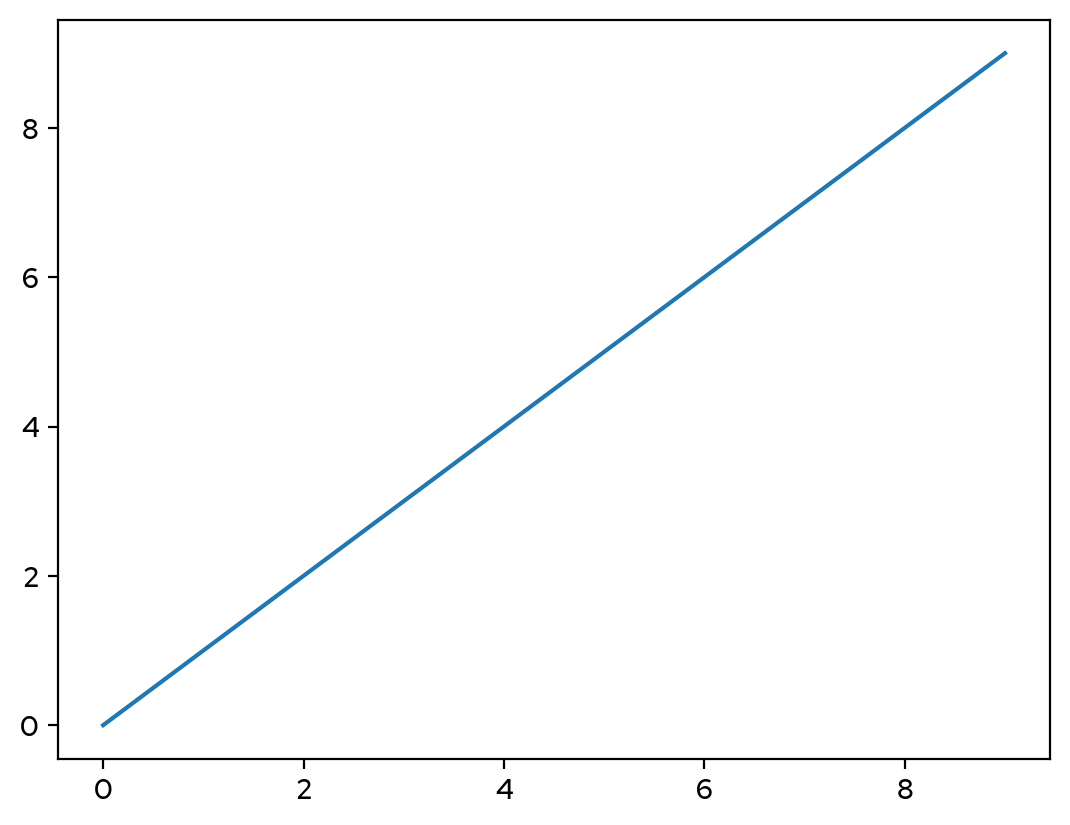

In [3]:
plt.plot(np.arange(10))

In [4]:
whoi_colors = ['#00B7BD', '#EE5340', '#0069b1', '#041e42']

In [5]:
def lighten_color(hex_color, saturation_scale=0.5, lightness_scale=1.5):
    """
    Lighten a hex color similar to seaborn's tab20 palette
    
    Args:
        hex_color: Hex color string (e.g., '#1f77b4')
        saturation_scale: Multiply saturation by this (default 0.5)
        lightness_scale: Multiply lightness by this (default 1.5)
    """
    # Remove '#' if present
    hex_color = hex_color.lstrip('#')
    
    # Convert hex to RGB (0-1 range)
    r, g, b = tuple(int(hex_color[i:i+2], 16) / 255.0 for i in (0, 2, 4))
    
    # Convert RGB to HLS
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    
    # Adjust saturation and lightness
    s_new = min(1.0, s * saturation_scale)
    l_new = min(1.0, l * lightness_scale)
    
    # Convert back to RGB
    r_new, g_new, b_new = colorsys.hls_to_rgb(h, l_new, s_new)
    
    # Convert to hex
    return '#{:02x}{:02x}{:02x}'.format(
        int(r_new * 255),
        int(g_new * 255),
        int(b_new * 255)
    )

In [6]:
colors = [
    whoi_colors[0],
    lighten_color(whoi_colors[0], lightness_scale=2),
    whoi_colors[1],
    lighten_color(whoi_colors[1], lightness_scale=1.4, saturation_scale=1)
]

In [7]:
colors

['#00B7BD', '#9cdbde', '#EE5340', '#f7b6ae']

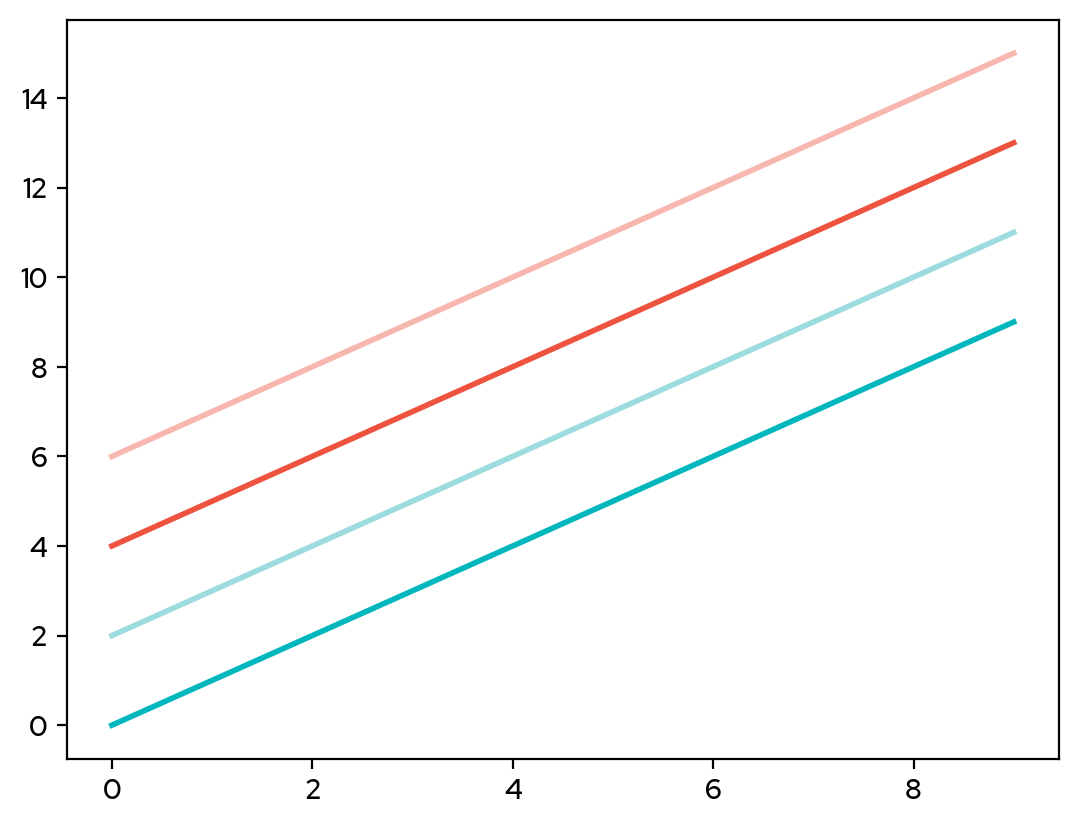

In [8]:
plt.plot(np.arange(0,10), lw=2, c=colors[0])
plt.plot(np.arange(2,12), lw=2, c=colors[1])
plt.plot(np.arange(4,14), lw=2, c=colors[2])
plt.plot(np.arange(6,16), lw=2, c=colors[3])

### load environment data

In [9]:
fn = f"{os.environ['NESCAFE23_DATADIR']}environment_data/map_bathy.nc"
bathy = xr.open_dataset(fn)["elevation"]

fn = f"{os.environ['NESCAFE23_DATADIR']}environment_data/FCTD_SoundSpeed_Colosi_v2.mat"
fctd = tools.get_fctd(fn=fn, r_smooth=3000)

fn = f"{os.environ['NESCAFE23_DATADIR']}environment_data/dt_global_twosat_phy_l4_20230430_vDT2024.nc"
ssh = xr.open_dataset(fn)

/home/john.ragland/Code/NESMA/NESCAFE23/.venv/bin/python: No module named pip


In [10]:
dss = tools.open_receptions()

  0%|          | 0/23 [00:00<?, ?it/s]

100%|██████████| 23/23 [00:16<00:00,  1.39it/s]


In [11]:
ssh_slice = (
    ssh["sla"]
    .isel({"time": 0})
    .sel({"latitude": slice(38, 50), "longitude": slice(-70, -50)})
)

In [10]:
fn = f"{os.environ['NESCAFE23_DATADIR']}environment_data/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_1773078040918.nc"
ssh_full = xr.open_dataset(fn)

ssh_n23 = ssh_full.sel({'time':pd.Timestamp('2023-04-30')})['adt']
ssh_fctd = ssh_full.sel({'time':pd.Timestamp('2023-05-30')})['adt']

In [16]:
ssh_n23

<xarray.DataArray 'adt' (latitude: 40, longitude: 56)> Size: 9kB
[2240 values with dtype=float32]
Coordinates:
  * latitude   (latitude) float32 160B 36.06 36.19 36.31 ... 40.69 40.81 40.94
  * longitude  (longitude) float32 224B -65.94 -65.81 -65.69 ... -59.19 -59.06
    time       datetime64[ns] 8B 2023-04-30
Attributes:
    units:          m
    standard_name:  sea_surface_height_above_geoid
    long_name:      Absolute dynamic topography
    comment:        The absolute dynamic topography is the sea surface height...
    grid_mapping:   crs

In [23]:
from scipy import io
ssh_mat = {
    "n23": {
        "ssh": ssh_n23.values,
        "time": pd.Timestamp(ssh_n23.time.values).strftime('%Y%m%d:%H%M%S'),
        "attrs": ssh_n23.attrs
    },
    "fctd": {
        "ssh": ssh_fctd.values,
        "time": pd.Timestamp(ssh_fctd.time.values).strftime('%Y%m%d:%H%M%S'),
        "attrs": ssh_fctd.attrs
    },
    "latitude": ssh_full.latitude.values,
    "longitude": ssh_full.longitude.values
}

io.savemat('ssh_n23_fctd.mat', ssh_mat)

In [28]:
fig, ax = plt.subplots()
cs_n23 = ax.contour(ssh_n23.longitude.values, ssh_n23.latitude.values, ssh_n23.values, levels=[0.25])
cs_fctd = ax.contour(ssh_fctd.longitude.values, ssh_fctd.latitude.values, ssh_fctd.values, levels=[0.25])
plt.close(fig)

# Keep segments separate — each is a continuous line
n23_segments  = [p.vertices for p in cs_n23.get_paths()]   # list of Nx2 arrays
fctd_segments = [p.vertices for p in cs_fctd.get_paths()]  # list of Nx2 arrays

# Access individual segments by index
# e.g. the longest segment (likely the main curve):
longest_n23  = max(n23_segments,  key=len)
longest_fctd = max(fctd_segments, key=len)

n23_x,  n23_y  = longest_n23[:, 0],  longest_n23[:, 1]
fctd_x, fctd_y = longest_fctd[:, 0], longest_fctd[:, 1]

In [41]:
from matplotlib.path import Path

def split_path_segments(contour_set):
    """Split a contour path into continuous segments using path codes."""
    segments = []
    for path in contour_set.get_paths():
        # MOVETO (code=1) indicates the start of a new segment
        split_indices = np.where(path.codes == Path.MOVETO)[0]
        
        for i, start in enumerate(split_indices):
            end = split_indices[i + 1] if i + 1 < len(split_indices) else len(path.vertices)
            seg = path.vertices[start:end]
            segments.append(seg)
    
    return segments

n23_segments  = split_path_segments(cs_n23)
fctd_segments = split_path_segments(cs_fctd)

# Inspect what you have
for i, seg in enumerate(n23_segments):
    print(f"n23  segment {i}: {len(seg)} points, "
          f"x=[{seg[:,0].min():.1f}, {seg[:,0].max():.1f}], "
          f"y=[{seg[:,1].min():.1f}, {seg[:,1].max():.1f}]")

n23  segment 0: 16 points, x=[-65.7, -64.6], y=[36.1, 36.4]
n23  segment 1: 16 points, x=[-59.4, -59.1], y=[37.4, 38.7]
n23  segment 2: 70 points, x=[-65.9, -59.1], y=[38.3, 40.1]


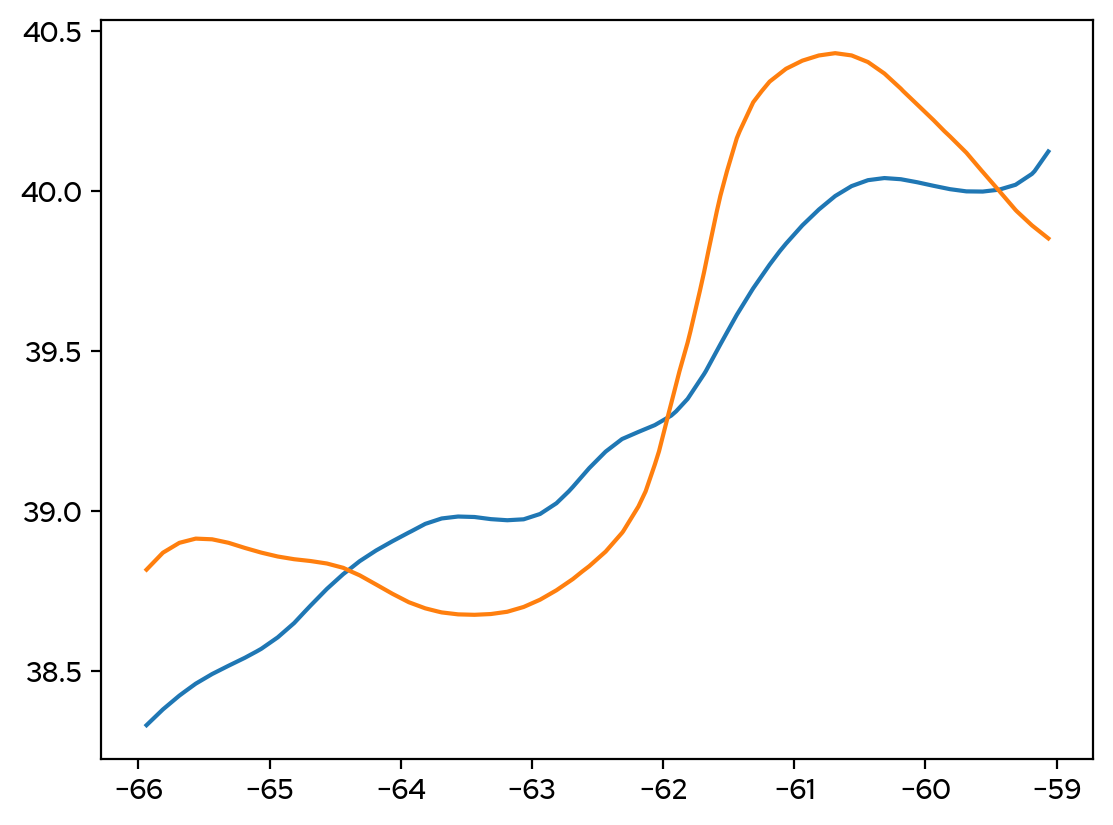

In [47]:
plt.plot(n23_segments[-1][:, 0], n23_segments[-1][:, 1])
plt.plot(fctd_segments[1][:, 0], fctd_segments[1][:, 1])

In [48]:
from scipy import io

io.savemat("n23_fctd_ssh_contours.mat", {'n23_segments':{'lon':n23_segments[-1][:, 0], 'lat':n23_segments[-1][:, 1]},
                                         'fctd_segments':{'lon':fctd_segments[1][:, 0], 'lat':fctd_segments[1][:, 1]}})

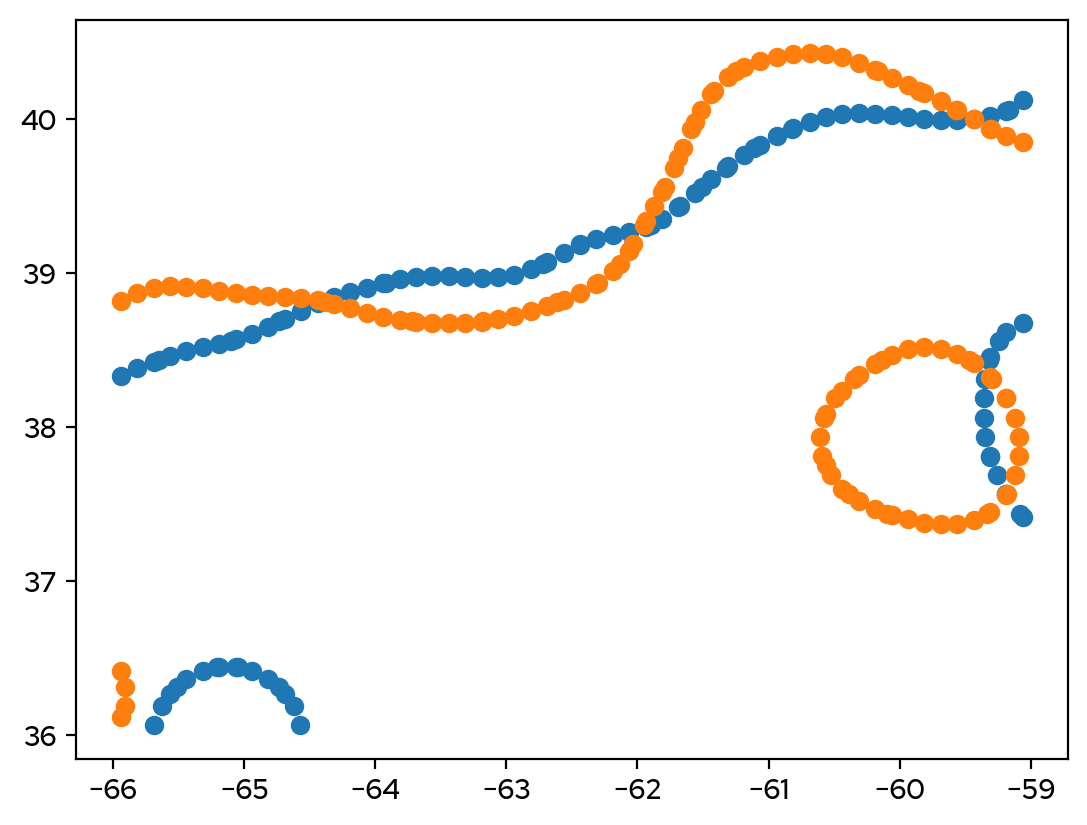

In [32]:
plt.scatter(n23_x, n23_y)
plt.scatter(fctd_x, fctd_y)

- Bathymetry data from GEBCO (will eventually be hi-res map from Brenden)
- FCTD is from Matthew Alford
- sea surface height is from copernicus, global ocean gridded sea surface height.

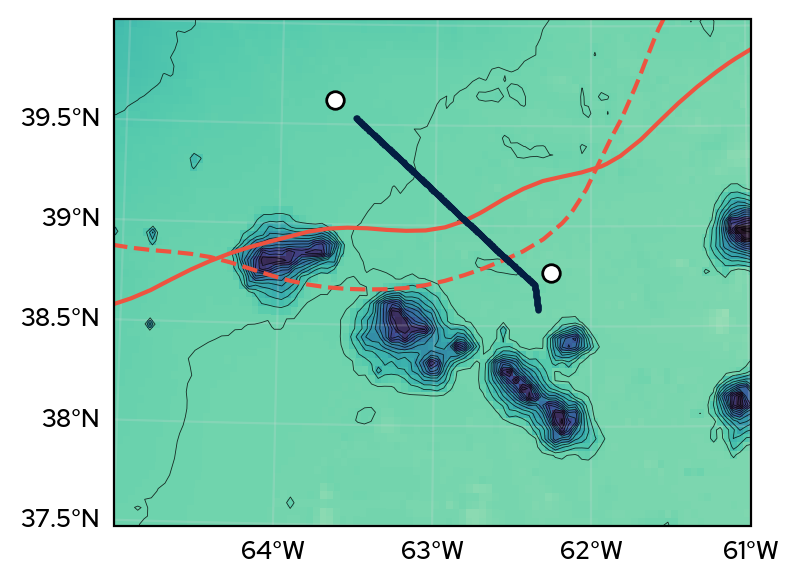

In [13]:
plt.rcParams["text.usetex"] = False
plt.rcParams["font.size"] = 9

coords = {
    "SION": [39 + 37.194 / 60, -63 - 39.427 / 60],
    "SIOE": [38 + 45.906 / 60, -62 - 15.626 / 60],
}

fig = plt.figure(figsize=(5, 3))

ax1 = fig.add_subplot(1, 1, 1, 
    projection=ccrs.Orthographic(central_longitude=-62, central_latitude=35)
)
ax1.set_extent([-65, -61, 37.5, 40], ccrs.Geodetic())
# ax1.coastlines()


## MAP
plt.sca(ax1)
# Add gridlines with labels only on bottom and left
gl = ax1.gridlines(
    draw_labels=True,
    dms=False,
    x_inline=False,
    y_inline=False,
    color="#dddddd",
    alpha=0.2,
)
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = True
gl.left_labels = True

# Add axis labels
ax1.set_xlabel("Longitude", transform=ax1.transAxes)
ax1.set_ylabel("Latitude", transform=ax1.transAxes)

# Bathymetry
bathy_plot = (-bathy[::10,::10]).plot(
    cmap='mako',
    transform=ccrs.PlateCarree(),
    ax=ax1,
    vmax=6000,
    vmin=500,
    add_colorbar=False,
    rasterized=True,
)  # cbar_kwargs = {'label':'depth [m]'}, alpha=1, rasterized=True)

# cbar = plt.colorbar(bathy_plot, ax=ax1, boundaries=np.linspace(1000,5000,256), label='depth [m]')
# cbar.ax.invert_yaxis()
# cbar.ax.set_yticks(np.arange(1000,5001,1000))

bathy[::10,::10].plot.contour(
    x="lon",
    y="lat",
    transform=ccrs.PlateCarree(),
    ax=ax1,
    colors="k",
    linewidths=0.3,
    alpha=0.8,
    levels=np.linspace(-5000, -1000, 15),
    linestyles="-",
)

# FCTD
plt.scatter(
    x=fctd["longitude"],
    y=fctd["latitude"],
    c=whoi_colors[3],
    transform=ccrs.PlateCarree(),
    s=5,
    lw=0,
    zorder=100,
)
#plt.text(
#    -64-0.75,
#    39.25 - 0.2,
##    "Hydrographic\nSurvey",
#    transform=ccrs.PlateCarree(),
#    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round"),
#)

# Sea Surface Height
#ssh_slice.plot.contour(
#    transform=ccrs.PlateCarree(), levels=[0.25], colors=colors[2], linewidths=2
#)


ssh_n23.plot.contour(transform=ccrs.PlateCarree(), x='longitude', y='latitude', levels = [0.25], colors=colors[2], linestyles='solid')
ssh_fctd.plot.contour(transform=ccrs.PlateCarree(), x='longitude', y='latitude', levels = [0.25], colors=colors[2], linestyles='dashed')
plt.title("")
# Moorings
mooring_names = {
    'SION':'Acoustic\nReceiver',
    'SIOE':'Acoustic\nSource'
}
for mooring in coords.keys():
    ax1.scatter(
        coords[mooring][1],
        coords[mooring][0],
        transform=ccrs.PlateCarree(),
        c="w",
        edgecolor="k",
        lw=1,
        s=40,
        zorder=1000,
    )
    #ax1.text(
    #    coords[mooring][1] + 0.25,
    #    coords[mooring][0] + 0.1,
    #    mooring_names[mooring],
    #    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round"),
    #    transform=ccrs.PlateCarree(),
    #)

# legend
#custom_lines = [Line2D([0], [0], color=colors[2], lw=2)]
#leg = ax1.legend(custom_lines, ["0.25 m SSH contour"], loc='lower left')
#frame = leg.get_frame()
#frame.set_alpha(1.0)  # or any transparency value 0–1

#plt.xlabel('Longitude [ $^\\circ$ ]')
#plt.ylabel('Latitude [ $^\\circ$ ]')

plt.tight_layout()

#fig.savefig("../../figures/presentation_figures/Map2.pdf", dpi=500)

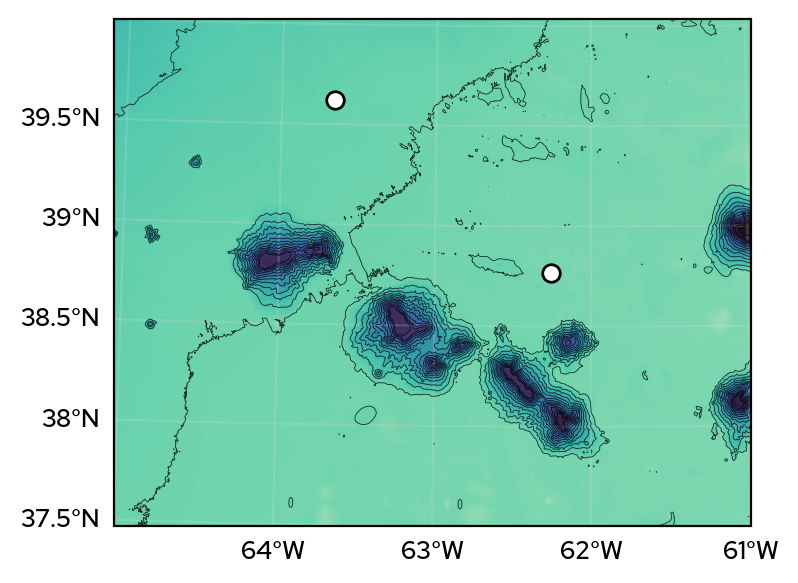

In [17]:
plt.rcParams["text.usetex"] = False
plt.rcParams["font.size"] = 9

coords = {
    "SION": [39 + 37.194 / 60, -63 - 39.427 / 60],
    "SIOE": [38 + 45.906 / 60, -62 - 15.626 / 60],
}

fig = plt.figure(figsize=(5, 3))

ax1 = fig.add_subplot(1, 1, 1, 
    projection=ccrs.Orthographic(central_longitude=-62, central_latitude=35)
)
ax1.set_extent([-65, -61, 37.5, 40], ccrs.Geodetic())
# ax1.coastlines()


## MAP
plt.sca(ax1)
# Add gridlines with labels only on bottom and left
gl = ax1.gridlines(
    draw_labels=True,
    dms=False,
    x_inline=False,
    y_inline=False,
    color="#dddddd",
    alpha=0.2,
)
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = True
gl.left_labels = True

# Add axis labels
ax1.set_xlabel("Longitude", transform=ax1.transAxes)
ax1.set_ylabel("Latitude", transform=ax1.transAxes)

# Bathymetry
bathy_plot = (-bathy).plot(
    cmap='mako',
    transform=ccrs.PlateCarree(),
    ax=ax1,
    vmax=6000,
    vmin=500,
    add_colorbar=False,
    rasterized=True,
)  # cbar_kwargs = {'label':'depth [m]'}, alpha=1, rasterized=True)

# cbar = plt.colorbar(bathy_plot, ax=ax1, boundaries=np.linspace(1000,5000,256), label='depth [m]')
# cbar.ax.invert_yaxis()
# cbar.ax.set_yticks(np.arange(1000,5001,1000))

bathy.plot.contour(
    x="lon",
    y="lat",
    transform=ccrs.PlateCarree(),
    ax=ax1,
    colors="k",
    linewidths=0.3,
    alpha=0.8,
    levels=np.linspace(-5000, -1000, 15),
    linestyles="-",
)

# FCTD
#plt.scatter(
#    x=fctd["longitude"],
#    y=fctd["latitude"],
#    c=whoi_colors[3],
#    transform=ccrs.PlateCarree(),
#    s=5,
#    lw=0,
#    zorder=100,
#)
#plt.text(
#    -64-0.75,
#    39.25 - 0.2,
##    "Hydrographic\nSurvey",
#    transform=ccrs.PlateCarree(),
#    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round"),
#)

# Sea Surface Height
#ssh_slice.plot.contour(
#    transform=ccrs.PlateCarree(), levels=[0.25], colors=colors[2], linewidths=2
#)


#ssh_n23.plot.contour(transform=ccrs.PlateCarree(), x='longitude', y='latitude', levels = [0.25], colors=colors[2], linestyles='solid')
#ssh_fctd.plot.contour(transform=ccrs.PlateCarree(), x='longitude', y='latitude', levels = [0.25], colors=colors[2], linestyles='dashed')
plt.title("")
# Moorings
mooring_names = {
    'SION':'Acoustic\nReceiver',
    'SIOE':'Acoustic\nSource'
}
for mooring in coords.keys():
    ax1.scatter(
        coords[mooring][1],
        coords[mooring][0],
        transform=ccrs.PlateCarree(),
        c="w",
        edgecolor="k",
        lw=1,
        s=40,
        zorder=1000,
    )
    #ax1.text(
    #    coords[mooring][1] + 0.25,
    #    coords[mooring][0] + 0.1,
    #    mooring_names[mooring],
    #    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round"),
    #    transform=ccrs.PlateCarree(),
    #)

# legend
#custom_lines = [Line2D([0], [0], color=colors[2], lw=2)]
#leg = ax1.legend(custom_lines, ["0.25 m SSH contour"], loc='lower left')
#frame = leg.get_frame()
#frame.set_alpha(1.0)  # or any transparency value 0–1

#plt.xlabel('Longitude [ $^\\circ$ ]')
#plt.ylabel('Latitude [ $^\\circ$ ]')

plt.tight_layout()

fig.savefig("../../figures/Map_backround_plate.pdf", dpi=500)

In [ ]:
# Global context inset figure
fig_global = plt.figure(figsize=(4, 4))

# Use Orthographic projection centered on the North Atlantic
ax_global = fig_global.add_subplot(1, 1, 1, 
                                     projection=ccrs.Orthographic(central_longitude=-40, 
                                                                   central_latitude=30))

# Set global extent first
ax_global.set_global()


# Your desired extent
lon_min, lon_max, lat_min, lat_max = -100, -20, 20, 70

# Create boundary points along your extent
lons_bottom = np.linspace(lon_min, lon_max, 100)
lons_top = np.linspace(lon_max, lon_min, 100)
lats_left = np.linspace(lat_min, lat_max, 100)
lats_right = np.linspace(lat_max, lat_min, 100)

# Create the boundary path
verts = list(zip(lons_bottom, [lat_min]*100)) + \
        list(zip([lon_max]*100, lats_left)) + \
        list(zip(lons_top, [lat_max]*100)) + \
        list(zip([lon_min]*100, lats_right))

boundary = mpath.Path(verts)
ax_global.set_boundary(boundary, transform=ccrs.PlateCarree())


# Add coastlines and land features
ax_global.coastlines(resolution='50m', linewidth=0.5)
ax_global.add_feature(cfeature.LAND.with_scale('50m'), facecolor='lightgray', alpha=1)
ax_global.add_feature(cfeature.OCEAN.with_scale('50m'), facecolor=whoi_colors[3], alpha=1)

# Add gridlines
ax_global.gridlines(color='gray', alpha=0.3, linestyle='--')

# Highlight the detailed map region
# Define the region boundaries from the main map
lon_min, lon_max = -65, -61
lat_min, lat_max = 37.5, 40

# Create a rectangle for the highlighted region
from matplotlib.patches import Rectangle
import matplotlib.patches as mpatches

# Plot the box showing the detailed region
rect_lons = [lon_min, lon_max, lon_max, lon_min, lon_min]
rect_lats = [lat_min, lat_min, lat_max, lat_max, lat_min]

ax_global.plot(rect_lons, rect_lats, 
               color=whoi_colors[1],
               linewidth=1, 
               transform=ccrs.PlateCarree(),
               zorder=100)

# Fill the rectangle to make it more visible
ax_global.fill(rect_lons, rect_lats,
               color=whoi_colors[1],
               alpha=1,
               transform=ccrs.PlateCarree(),
               zorder=99)

ax_global.set_extent([-100, -20, 0, 70], ccrs.PlateCarree())

plt.tight_layout()

fig_global.savefig("../../figures/presentation_figures/map_inset.pdf", dpi=300, transparent=True)